# Multi-delay ASL: perfusion and arrival time

## 1. Problem

The goal is to reconstruct **two spatial physical fields**, cerebral blood flow (CBF) and arterial transit time (ATT), from seven weak difference-magnetization measurements. Labelled blood water is an endogenous tracer. Delayed delivery changes the shape of the curve, while perfusion and relaxation jointly change its amplitude.

This review uses the complete bound five-slice author demonstration acquisition. It actively runs the cleaned local method and identifies the original-code comparison separately. Neither reconstruction is independent physiological truth. No paper-reported performance numbers are used as evidence for this acquisition.

The selected model is Buxton finite-bolus transport with effective relaxation, as implemented by the author ASL toolkit. The scan is supplied at the shortest echo (13.56 ms); transverse-relaxation effects are not separately corrected. This limitation and signal noise matter when interpreting fitted values.

In [1]:
import os,sys,time,json,subprocess
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if not (ROOT/'data/raw_data.npz').exists(): raise RuntimeError('Run from task root or its notebooks directory')
os.chdir(ROOT)
sys.path.insert(0,str(ROOT))
from src.preprocessing import load_observations
from src.physics_model import buxton_signal,forward_volume,LABEL_DURATION,POST_LABEL_DELAY
from src.solvers import reconstruct,single_delay_approximation
from src.visualization import metric_pair,summarize,map_panel,save_figure
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110})
FIGURES=Path(os.environ['IMAGING_FIGURE_DIR']) if os.environ.get('IMAGING_FIGURE_DIR') else None
def show(fig,name):
    save_figure(fig,FIGURES,name)
    display(fig)
    plt.close(fig)
print('Active reconstruction mode; Python',sys.version.split()[0],'NumPy',np.__version__)


Active reconstruction mode; Python 3.11.11 NumPy 2.4.6


## 2. Data

The public NPZ contains only the seven acquired magnetization images, M0 calibration, and fixed brain-region mask. All signal values preserve the author's float32 storage. The arrays are batch first. The seven LD/PLD pairs, in milliseconds, are paired in acquisition order. M0 and signal have the same scanner magnetization units; their absolute values are not proton-density measurements.

The native demonstration volume has five slices of 35×35 samples at the header's 1 mm grid spacing. This is the supplied demonstration grid, rather than a claim about native scanner resolution. Scanner/subject details were not supplied. Negative difference signals are retained. Only the first echo is exposed; additional echoes are not privileged solver input.

{'magnetization': ((1, 7, 5, 35, 35), 'float32'), 'm0': ((1, 5, 35, 35), 'float32'), 'mask': ((1, 5, 35, 35), 'uint8')}
Masked voxels: 5800
LD [ms]: [100.0, 100.0, 150.0, 150.0, 400.0, 800.0, 1800.0]
PLD [ms]: [170.0, 270.0, 370.0, 520.0, 670.0, 1070.0, 1870.0]


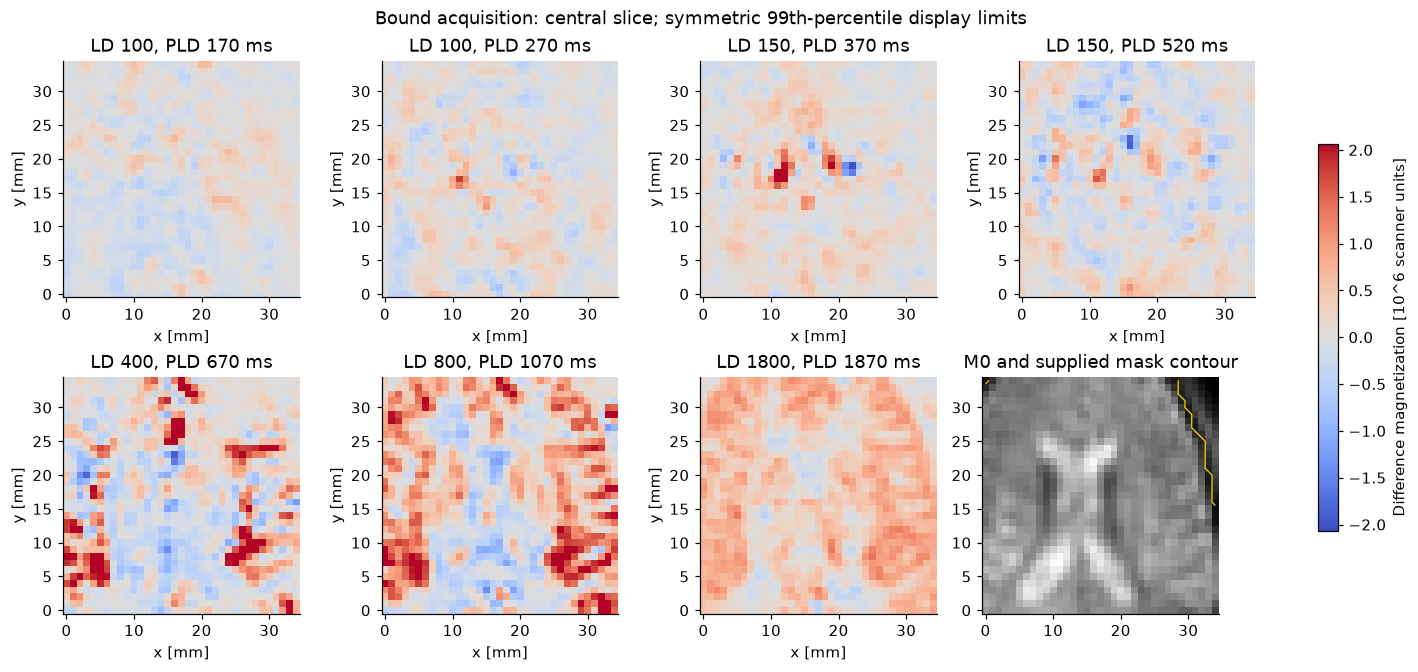

In [2]:
data=load_observations()
mask=data['mask'][0]>0
print({k:(v.shape,str(v.dtype)) for k,v in data.items()})
print('Masked voxels:',int(mask.sum()))
print('LD [ms]:',LABEL_DURATION.tolist())
print('PLD [ms]:',POST_LABEL_DELAY.tolist())
fig,axes=plt.subplots(2,4,figsize=(13,6),layout='constrained')
z=2;bound=np.percentile(np.abs(data['magnetization'][0,:,z]),99)
for i,ax in enumerate(axes.flat[:7]):
    im=ax.imshow(data['magnetization'][0,i,z]/1e6,origin='lower',cmap='coolwarm',vmin=-bound/1e6,vmax=bound/1e6)
    ax.set_title(f'LD {LABEL_DURATION[i]:.0f}, PLD {POST_LABEL_DELAY[i]:.0f} ms')
    ax.set_xlabel('x [mm]');ax.set_ylabel('y [mm]')
axes.flat[7].imshow(data['m0'][0,z]/1e6,origin='lower',cmap='gray')
axes.flat[7].contour(mask[z],levels=[.5],colors='gold',linewidths=.8)
axes.flat[7].set_title('M0 and supplied mask contour')
fig.colorbar(im,ax=axes.flat[:7].tolist(),label='Difference magnetization [10^6 scanner units]',shrink=.7)
fig.suptitle('Bound acquisition: central slice; symmetric 99th-percentile display limits')
show(fig,'01_acquisition')


## 3. Physics

Let f be flow in mL/g/ms, a the transit time in ms, M0 equilibrium magnetization in scanner units, alpha=0.85 labelling efficiency, lambda=0.98 mL/g the water partition coefficient, and T=1650 ms the blood longitudinal relaxation time. Set t=tau+w for labelling duration tau and post-labelling delay w. The effective relaxation time is

$$T_e=(T^{-1}+f/\lambda)^{-1}.$$

A labelled bolus is delivered during [a,a+tau]. With arrival integration variable v, the measured difference signal after arrival is

$$s(t)=2\alpha M_0 f\exp(-a/T)\int_a^{\min(t,a+\tau)}\exp(-(t-v)/T_e)\,dv.$$

Before arrival s=0. Evaluating this integral gives accumulation during delivery and exponential washout afterward. The independent physics test evaluates the integral with numerical quadrature and checks the local closed form at arrival, within delivery and after delivery. Positive CBF in clinical units equals 6,000,000 f: 100 g per g times 60,000 ms per minute.

The acquisition varies **both** tau and w. Connecting the seven observations as one smooth time trace is therefore only a visual aid; they are seven different finite-bolus preparations.

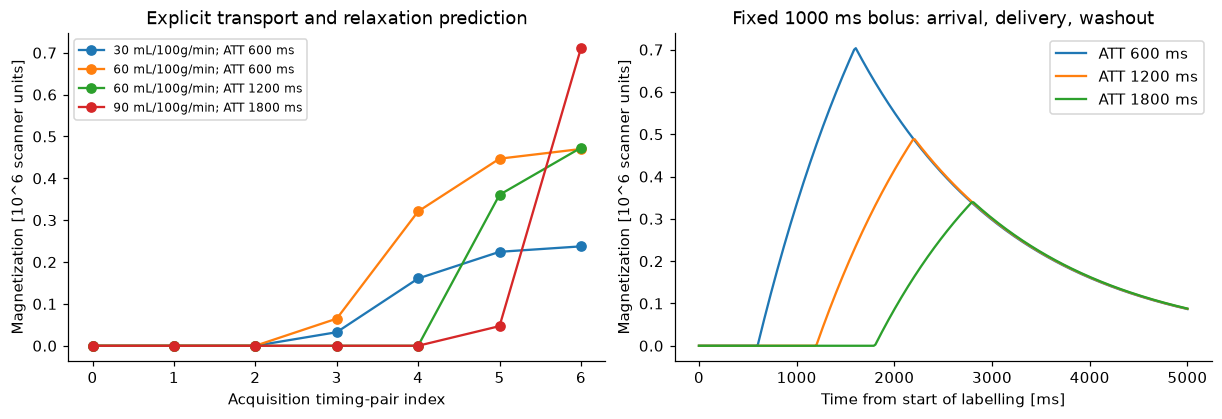

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,3.7),layout='constrained')
for clinical,a in [(30,600),(60,600),(60,1200),(90,1800)]:
    s=buxton_signal(LABEL_DURATION,POST_LABEL_DELAY,8e7,clinical/6e6,a)
    axes[0].plot(np.arange(7),s/1e6,'o-',label=f'{clinical} mL/100g/min; ATT {a} ms')
axes[0].set(xlabel='Acquisition timing-pair index',ylabel='Magnetization [10^6 scanner units]',title='Explicit transport and relaxation prediction')
axes[0].legend(fontsize=8)
t=np.linspace(0,5000,300)
for a in [600.,1200.,1800.]:
    s=buxton_signal(np.full(t.size,1000.),t-1000.,8e7,1e-5,a)
    axes[1].plot(t,s/1e6,label=f'ATT {a:.0f} ms')
axes[1].set(xlabel='Time from start of labelling [ms]',ylabel='Magnetization [10^6 scanner units]',title='Fixed 1000 ms bolus: arrival, delivery, washout')
axes[1].legend()
show(fig,'02_physics')


## 4. Method

Every masked voxel solves the bounded objective

$$\min_{f,a}\;\sum_{j=1}^{7}[s_j(f,a)-y_j]^2.$$

The sum is unweighted because a measurement-noise variance was not provided. There is no spatial regularizer. The standard fit initializes (f,a)=(10^-5,1000 ms), with bounds (0,0) to (1,5000 ms), preserving the original mapper's defaults. Bounded SciPy trust-region reflective least squares uses a numerical Jacobian and default convergence tolerances. A failed convergence returns zero parameters, matching the original implementation.

The original mapper stores fit parameters in float32 shared memory. This port preserves that rounding and returns float64 maps after unit conversion. Its optional upstream `cbf_norm` multiplies raw flow by 3,600,000, which conflicts with the stated mL/100g/min units. We compare with the original **raw** fitted flow and explicitly convert it with the dimensionally correct 6,000,000 factor. The fitting process is preserved; the inconsistent optional normalization is not silently propagated.

The following cell performs a fresh complete reconstruction from the public observations. It does not load a cached reconstruction.

In [4]:
started=time.perf_counter()
fresh=reconstruct(**data)
standard_seconds=time.perf_counter()-started
np.savez_compressed(ROOT/'output/reconstruction.npz',**fresh)
with np.load(ROOT/'notebooks/reference_outputs/upstream_reconstruction.npz',allow_pickle=False) as z:
    upstream={k:z[k].copy() for k in fresh}
metrics=summarize(fresh,upstream)
predicted=forward_volume(**fresh,m0=data['m0'])
valid=np.broadcast_to(data['mask'][:,None]>0,predicted.shape)
residual=predicted-data['magnetization']
signal_l2=float(np.linalg.norm(residual[valid])/np.linalg.norm(data['magnetization'][valid].astype(np.float64)))
print('Fresh standard runtime [s]:',standard_seconds)
print(json.dumps(metrics,indent=2))
print('Fresh signal relative L2:',signal_l2)
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_metrics.npz',map_metrics=np.array(list(metrics.values())),signal_relative_l2=np.array(signal_l2),runtime_seconds=np.array(standard_seconds))
p=subprocess.run([sys.executable,'evaluation/judge.py','--prediction','output/reconstruction.npz','--report','output/judge_report.json'],capture_output=True,text=True)
judge=json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf8'))
assert p.returncode==0,judge
assert np.isclose(signal_l2,judge['metrics']['signal_relative_l2'],rtol=1e-12,atol=1e-15)
print('Standalone Judge:',judge['status'])


Fresh standard runtime [s]: 18.792070600000443
{
  "reconstruction_ncc": 1.0,
  "reconstruction_nrmse": 0.0,
  "arterial_transit_time_ncc": 1.0,
  "arterial_transit_time_nrmse": 0.0
}
Fresh signal relative L2: 0.6146257649104498
Standalone Judge: pass


## 5. Results

The reference here is the independently rerun author implementation on these exact observations. Map agreement measures extraction fidelity. It does not measure error against known patient physiology.

First inspect the complete fresh fields. The perfusion display uses a fixed 0–250 clinical-unit range to retain tissue contrast; larger values remain in the saved output and are counted below. The ATT display spans the entire numerical range. Display limits do not clip evaluation data.

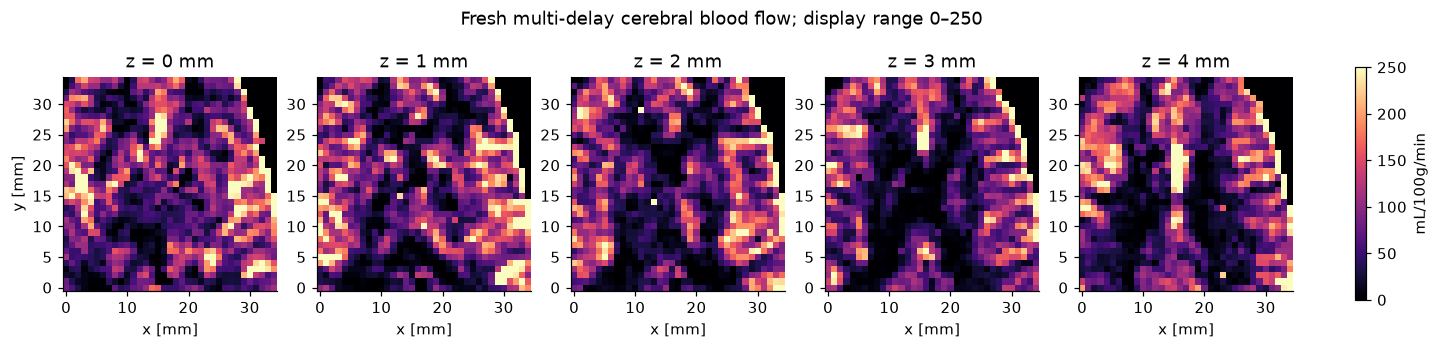

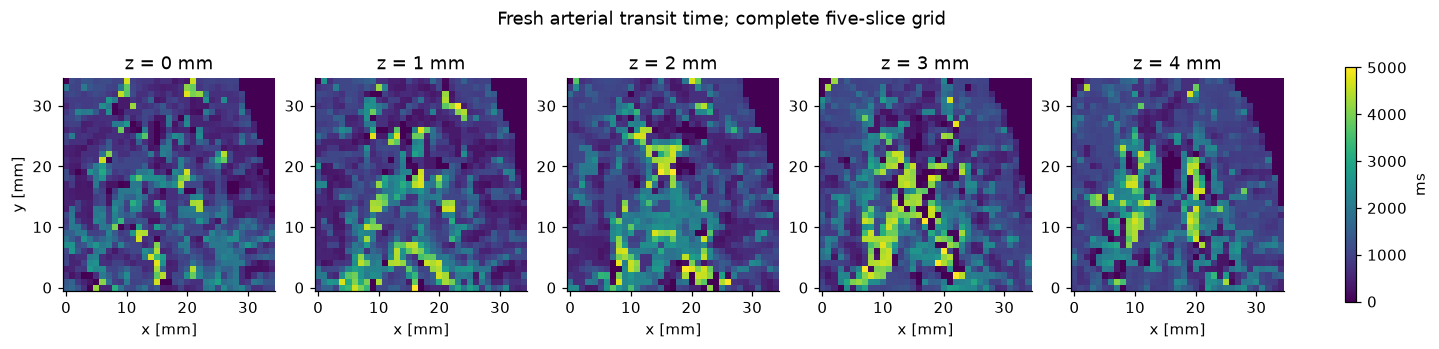

reconstruction masked min/median/max [6.0109544369940135e-18, 68.06078636145685, 4091.71509090811]
arterial_transit_time masked min/median/max [3.350749538943987e-11, 1051.61376953125, 4999.9833984375]
CBF >250 mL/100g/min: 226 of 5800


In [5]:
fig,_=map_panel(fresh['reconstruction'],'Fresh multi-delay cerebral blood flow; display range 0–250','mL/100g/min',0,250,'magma')
show(fig,'03_fresh_flow')
fig,_=map_panel(fresh['arterial_transit_time'],'Fresh arterial transit time; complete five-slice grid','ms',0,5000,'viridis')
show(fig,'04_fresh_arrival')
for k in fresh:
    print(k,'masked min/median/max',np.percentile(fresh[k][0][mask],[0,50,100]).tolist())
print('CBF >250 mL/100g/min:',int(np.count_nonzero(fresh['reconstruction'][0][mask]>250)),'of',int(mask.sum()))


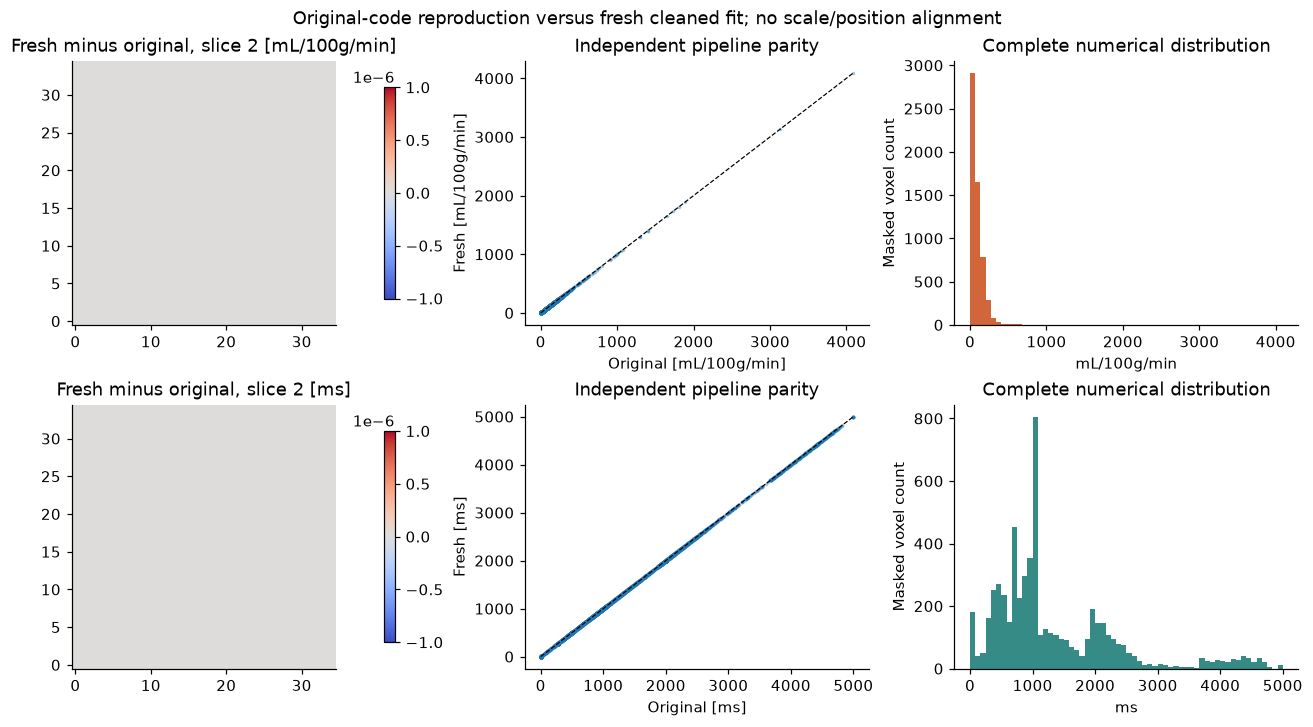

In [6]:
fig,axes=plt.subplots(2,3,figsize=(12,6.5),layout='constrained')
for row,(key,unit) in enumerate([('reconstruction','mL/100g/min'),('arterial_transit_time','ms')]):
    a=fresh[key][0];r=upstream[key][0];difference=a-r
    vmax=max(float(np.max(np.abs(difference))),1e-6)
    im=axes[row,0].imshow(difference[2],origin='lower',cmap='coolwarm',vmin=-vmax,vmax=vmax)
    axes[row,0].set_title(f'Fresh minus original, slice 2 [{unit}]');fig.colorbar(im,ax=axes[row,0],shrink=.8)
    axes[row,1].scatter(r[mask],a[mask],s=2,alpha=.3)
    lim=float(max(r.max(),a.max()));axes[row,1].plot([0,lim],[0,lim],'k--',lw=.8)
    axes[row,1].set(xlabel=f'Original [{unit}]',ylabel=f'Fresh [{unit}]',title='Independent pipeline parity')
    axes[row,2].hist(a[mask],bins=60,color=['#D1663A','#378B87'][row])
    axes[row,2].set(xlabel=unit,ylabel='Masked voxel count',title='Complete numerical distribution')
fig.suptitle('Original-code reproduction versus fresh cleaned fit; no scale/position alignment')
show(fig,'05_upstream_parity')


The residual analysis uses the physical model, all seven acquired timing pairs and the fixed mask. The fitted field reduces the relative L2 error compared with a zero-signal prediction, but substantial unexplained signal remains. Unknown noise variance, possible multi-compartment physiology and the shortest-echo approximation limit the single-compartment interpretation. Extreme values and near-boundary arrival times should be interpreted as fit instability or model limitations, rather than validated disease biomarkers.

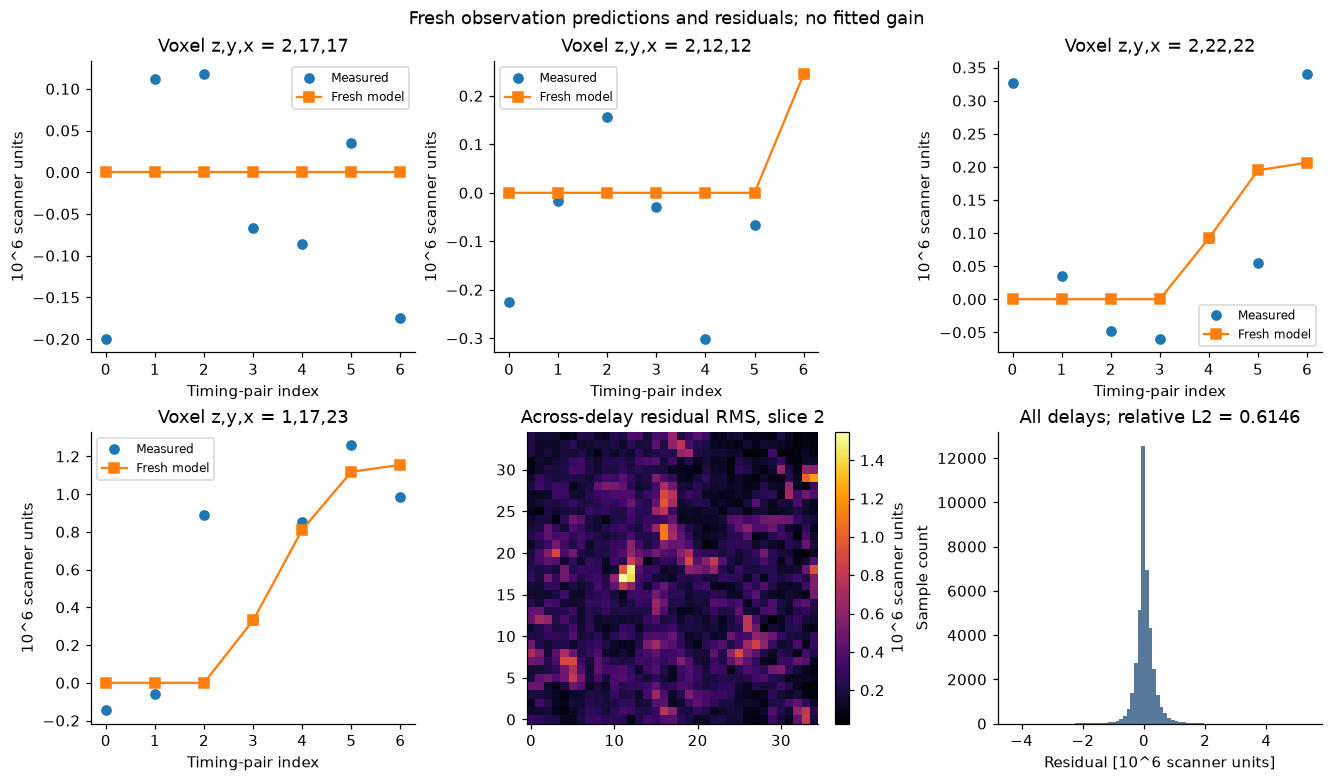

In [7]:
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained')
for j,(z,y,x) in enumerate([(2,17,17),(2,12,12),(2,22,22),(1,17,23)]):
    ax=axes.flat[j]
    ax.plot(np.arange(7),data['magnetization'][0,:,z,y,x]/1e6,'o',label='Measured')
    ax.plot(np.arange(7),predicted[0,:,z,y,x]/1e6,'s-',label='Fresh model')
    ax.set(xlabel='Timing-pair index',ylabel='10^6 scanner units',title=f'Voxel z,y,x = {z},{y},{x}')
    ax.legend(fontsize=8)
rms=np.sqrt(np.mean(residual[0]**2,axis=0))
im=axes.flat[4].imshow(rms[2]/1e6,origin='lower',cmap='inferno');axes.flat[4].set_title('Across-delay residual RMS, slice 2');fig.colorbar(im,ax=axes.flat[4],label='10^6 scanner units')
axes.flat[5].hist(residual[valid]/1e6,bins=80,color='#577A9B');axes.flat[5].set(xlabel='Residual [10^6 scanner units]',ylabel='Sample count',title=f'All delays; relative L2 = {signal_l2:.4f}')
fig.suptitle('Fresh observation predictions and residuals; no fitted gain')
show(fig,'06_observation_residuals')


We next compute new sensitivity experiments from the same observations. Changing labelling efficiency tests calibration dependence; changing the initial arrival time tests optimizer sensitivity. These are independent fresh local runs, not archived reconstructions. The single-delay curve uses only the final LD/PLD pair and assumes complete arrival and negligible perfusion washout; it is a deliberately labeled physical approximation.

In [8]:
experiments={'Standard alpha=.85':fresh}
experiment_seconds={'Standard alpha=.85':standard_seconds}
for name,kwargs in [('alpha=.75',{'efficiency':.75}),('alpha=.95',{'efficiency':.95}),('initial ATT=500 ms',{'initial':(1e-5,500.)})]:
    started=time.perf_counter();experiments[name]=reconstruct(**data,**kwargs);experiment_seconds[name]=time.perf_counter()-started
single=single_delay_approximation(**data)
comparison=[]
for name,result in experiments.items():
    alpha=.75 if name=='alpha=.75' else .95 if name=='alpha=.95' else .85
    yp=forward_volume(**result,m0=data['m0'],efficiency=alpha)
    rel=float(np.linalg.norm((yp-data['magnetization'])[valid])/np.linalg.norm(data['magnetization'][valid].astype(np.float64)))
    comparison.append([name,float(np.median(result['reconstruction'][0][mask])),float(np.median(result['arterial_transit_time'][0][mask])),rel,experiment_seconds[name]])
display(Markdown(chr(10).join(['|Fresh run|Median CBF [mL/100g/min]|Median ATT [ms]|Relative signal L2|Runtime [s]|','|---|---:|---:|---:|---:|']+['|'+str(r[0])+'|'+'|'.join(f'{v:.6g}' for v in r[1:])+'|' for r in comparison])))

|Fresh run|Median CBF [mL/100g/min]|Median ATT [ms]|Relative signal L2|Runtime [s]|
|---|---:|---:|---:|---:|
|Standard alpha=.85|68.0608|1051.61|0.614626|18.7921|
|alpha=.75|77.9376|1058.78|0.614938|21.5314|
|alpha=.95|60.7855|1049.79|0.614922|20.8528|
|initial ATT=500 ms|57.0645|499.883|0.630474|26.4949|

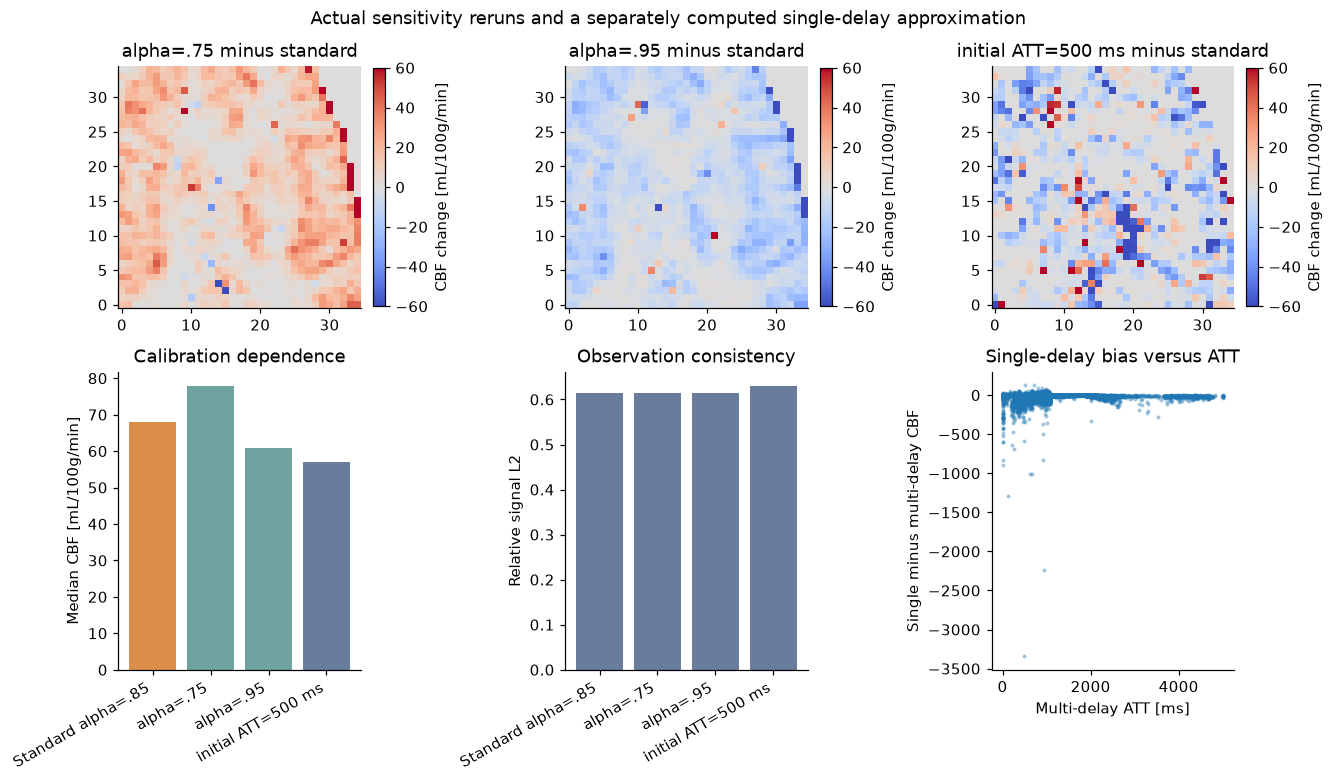

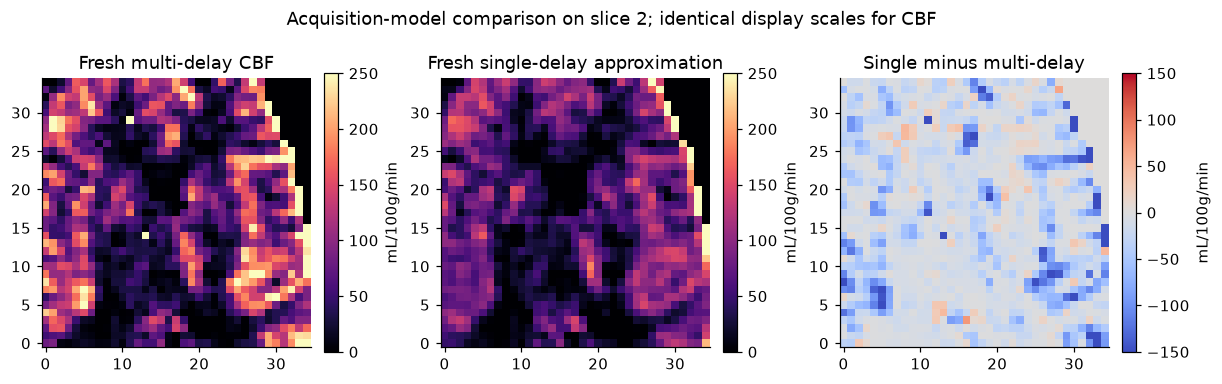

Scientific figures generated from current measurements: 8


In [9]:
fig,axes=plt.subplots(2,3,figsize=(12,7),layout='constrained')
for ax,(name,result) in zip(axes[0],list(experiments.items())[1:]):
    change=result['reconstruction'][0,2]-fresh['reconstruction'][0,2]
    im=ax.imshow(change,origin='lower',cmap='coolwarm',vmin=-60,vmax=60)
    ax.set_title(name+' minus standard');fig.colorbar(im,ax=ax,label='CBF change [mL/100g/min]',shrink=.8)
labels=[r[0] for r in comparison];x=np.arange(len(labels))
axes[1,0].bar(x,[r[1] for r in comparison],color=['#DB8D4A','#6EA3A0','#6EA3A0','#697C9B']);axes[1,0].set_xticks(x,labels,rotation=30,ha='right');axes[1,0].set(ylabel='Median CBF [mL/100g/min]',title='Calibration dependence')
axes[1,1].bar(x,[r[3] for r in comparison],color='#697C9B');axes[1,1].set_xticks(x,labels,rotation=30,ha='right');axes[1,1].set(ylabel='Relative signal L2',title='Observation consistency')
axes[1,2].scatter(fresh['arterial_transit_time'][0][mask],(single-fresh['reconstruction'])[0][mask],s=3,alpha=.3)
axes[1,2].set(xlabel='Multi-delay ATT [ms]',ylabel='Single minus multi-delay CBF',title='Single-delay bias versus ATT')
fig.suptitle('Actual sensitivity reruns and a separately computed single-delay approximation')
show(fig,'07_sensitivity')
fig,axes=plt.subplots(1,3,figsize=(11,3.5),layout='constrained')
for ax,a,title in zip(axes,[fresh['reconstruction'][0,2],single[0,2],single[0,2]-fresh['reconstruction'][0,2]],['Fresh multi-delay CBF','Fresh single-delay approximation','Single minus multi-delay']):
    im=ax.imshow(a,origin='lower',cmap='magma' if 'minus' not in title else 'coolwarm',vmin=0 if 'minus' not in title else -150,vmax=250 if 'minus' not in title else 150)
    ax.set_title(title);fig.colorbar(im,ax=ax,label='mL/100g/min',shrink=.8)
fig.suptitle('Acquisition-model comparison on slice 2; identical display scales for CBF')
show(fig,'08_single_delay_comparison')
if FIGURES is not None:
    np.savez_compressed(FIGURES/'numerical_sources.npz',magnetization=data['magnetization'],m0=data['m0'],mask=data['mask'],fresh_flow=fresh['reconstruction'],fresh_att=fresh['arterial_transit_time'],upstream_flow=upstream['reconstruction'],upstream_att=upstream['arterial_transit_time'],predicted_signal=predicted,residual=residual,single_delay_flow=single,efficiency75_flow=experiments['alpha=.75']['reconstruction'],efficiency95_flow=experiments['alpha=.95']['reconstruction'],initial500_flow=experiments['initial ATT=500 ms']['reconstruction'],sensitivity_summary=np.array([r[1:] for r in comparison]))
print('Scientific figures generated from current measurements:',8)


## 6. Conclusion

The fresh local implementation reproduces the independently executed original fit on the exact bound observations and passes both field comparisons and forward consistency. Independent finite-bolus quadrature checks the mathematical physics. CBF and ATT are evaluated separately, so agreement in only one quantity is insufficient.

This author demonstration supports a reproducible kinetic inverse task, not a claim of independently known tissue perfusion. Calibration sensitivity, initialization dependence and substantial residual signal show why method agreement alone cannot establish physiological accuracy. Every displayed alternative was actively computed. The original-code comparison, fresh standard fit, single-delay approximation and sensitivity runs remain separately labeled.

Provenance, the optional upstream normalization discrepancy, environments, numerical tolerances, signatures, validation commands and archive hashes are recorded in `test/validation.md`. Source mathematics and the public acquisition contract agree. The original full source and supplied paper remain in the private maintainer archive.